# Activity Recognition — Shared Sequence Preprocessing

This notebook constructs a deterministic, model-independent sequence
representation from the frozen canonical train and test windows.

The initial target is a paired watch representation containing separate
accelerometer and gyroscope arrays. Each valid sensor window will eventually be
resampled by timestamp to a fixed-length sequence.

This stage is responsible for:

- validating the frozen split and window protocol;
- applying the previously selected window-quality rules;
- pairing corresponding watch accelerometer and gyroscope windows;
- defining and validating timestamp-based resampling;
- saving unnormalized fixed-length arrays and traceable metadata.

This stage does not perform normalization, feature selection, augmentation,
model fitting, hyperparameter tuning, or test-set evaluation. Any transformation
that learns population parameters will be fitted later inside each model's
training folds.

## 1. Purpose, inputs, and fixed protocol

### 1.1 Imports and project paths

Preprocessing starts from the frozen train and test datasets in `modified/`.
It does not reload raw sensor files or recreate canonical windows.

We first locate and validate all required inputs before loading the larger
Parquet datasets.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd


CURRENT_DIR = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        candidate
        for candidate in [CURRENT_DIR, *CURRENT_DIR.parents]
        if (candidate / "baseline").is_dir()
        and (candidate / "modified").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the activity_project root."
    )

TRAIN_SAMPLES_PATH = (
    PROJECT_ROOT / "modified" / "train_samples.parquet"
)
TEST_SAMPLES_PATH = (
    PROJECT_ROOT / "modified" / "test_samples.parquet"
)
WINDOWED_META_PATH = (
    PROJECT_ROOT / "modified" / "windowed_split_meta.json"
)
SPLIT_META_PATH = (
    PROJECT_ROOT
    / "baseline"
    / "artifacts"
    / "split_meta.json"
)
DEVELOPMENT_FOLDS_PATH = (
    PROJECT_ROOT
    / "baseline"
    / "artifacts"
    / "development_folds.json"
)
OUTPUT_DIR = (
    PROJECT_ROOT / "modified" / "watch_pair_20hz"
)

required_inputs = {
    "Train samples": TRAIN_SAMPLES_PATH,
    "Test samples": TEST_SAMPLES_PATH,
    "Windowed-split metadata": WINDOWED_META_PATH,
    "Canonical-split metadata": SPLIT_META_PATH,
    "Development folds": DEVELOPMENT_FOLDS_PATH,
}

input_file_overview = pd.DataFrame(
    [
        {
            "input": name,
            "path": str(path.relative_to(PROJECT_ROOT)),
            "exists": path.exists(),
            "size_mib": (
                path.stat().st_size / 1024**2
                if path.exists()
                else np.nan
            ),
        }
        for name, path in required_inputs.items()
    ]
)

display(input_file_overview)

missing_inputs = [
    name
    for name, path in required_inputs.items()
    if not path.exists()
]

if missing_inputs:
    raise FileNotFoundError(
        f"Missing required inputs: {missing_inputs}"
    )

print("Project root:", PROJECT_ROOT)
print("Planned output directory:", OUTPUT_DIR)

,input,path,exists,size_mib
0,Train samples,modified/train_samples.parquet,True,234.470824
1,Test samples,modified/test_samples.parquet,True,59.357207
2,Windowed-split metadata,modified/windowed_split_meta.json,True,0.001219
3,Canonical-split metadata,baseline/artifacts/split_meta.json,True,0.001124
4,Development folds,baseline/artifacts/development_folds.json,True,0.001093


Project root: /Users/yairlutaty/dev/yair.lutaty/projects/activity_project
Planned output directory: /Users/yairlutaty/dev/yair.lutaty/projects/activity_project/modified/watch_pair_20hz


### 1.2 Validate frozen protocol metadata

The metadata files describe the team-defined train/test split, canonical
windowing protocol, exported datasets, and fixed development folds.

Before processing sensor rows, we verify that these records agree and that
every development subject belongs to exactly one validation fold.

In [2]:
split_meta = json.loads(
    SPLIT_META_PATH.read_text(encoding="utf-8")
)
windowed_meta = json.loads(
    WINDOWED_META_PATH.read_text(encoding="utf-8")
)
development_folds_meta = json.loads(
    DEVELOPMENT_FOLDS_PATH.read_text(encoding="utf-8")
)

train_subject_ids = [
    int(subject_id)
    for subject_id in split_meta["train_user_ids"]
]
test_subject_ids = [
    int(subject_id)
    for subject_id in split_meta["test_user_ids"]
]

validation_subjects_by_fold = {
    int(fold): [
        int(subject_id)
        for subject_id in subject_ids
    ]
    for fold, subject_ids
    in development_folds_meta[
        "validation_subject_ids_by_fold"
    ].items()
}

fold_subject_ids = [
    subject_id
    for subject_ids in validation_subjects_by_fold.values()
    for subject_id in subject_ids
]

FOLD_BY_SUBJECT = {
    subject_id: fold
    for fold, subject_ids
    in validation_subjects_by_fold.items()
    for subject_id in subject_ids
}

assert windowed_meta["columns"] == split_meta["columns"]
assert (
    windowed_meta["n_total_rows"]
    == split_meta["n_rows"]
)
assert (
    windowed_meta["n_train_rows"]
    == split_meta["n_train_rows"]
)
assert (
    windowed_meta["n_test_rows"]
    == split_meta["n_test_rows"]
)
assert (
    windowed_meta["n_train_windows"]
    + windowed_meta["n_test_windows"]
    == split_meta["n_windows"]
)
assert windowed_meta["window_s"] == split_meta["window_s"]
assert (
    windowed_meta["min_samples"]
    == split_meta["min_samples"]
)
assert (
    windowed_meta["train_subject_ids"]
    == train_subject_ids
)
assert (
    windowed_meta["test_subject_ids"]
    == test_subject_ids
)

assert set(train_subject_ids).isdisjoint(test_subject_ids)
assert len(fold_subject_ids) == len(train_subject_ids)
assert len(set(fold_subject_ids)) == len(fold_subject_ids)
assert sorted(fold_subject_ids) == sorted(train_subject_ids)
assert set(fold_subject_ids).isdisjoint(test_subject_ids)

protocol_overview = pd.Series({
    "Canonical window duration (s)": split_meta["window_s"],
    "Minimum samples per canonical window": split_meta["min_samples"],
    "Total sensor rows": split_meta["n_rows"],
    "Training sensor rows": split_meta["n_train_rows"],
    "Test sensor rows": split_meta["n_test_rows"],
    "Total sensor-specific windows": split_meta["n_windows"],
    "Training sensor-specific windows": (
        windowed_meta["n_train_windows"]
    ),
    "Test sensor-specific windows": (
        windowed_meta["n_test_windows"]
    ),
    "Development subjects": len(train_subject_ids),
    "Test subjects": len(test_subject_ids),
    "Development folds": len(validation_subjects_by_fold),
})

fold_overview = pd.DataFrame(
    [
        {
            "fold": fold,
            "n_validation_subjects": len(subject_ids),
            "validation_subject_ids": tuple(subject_ids),
        }
        for fold, subject_ids
        in sorted(validation_subjects_by_fold.items())
    ]
).set_index("fold")

display(protocol_overview.to_frame("value"))
display(fold_overview)

print("Frozen metadata validation passed.")

,value
Canonical window duration (s),5.0
Minimum samples per canonical window,50.0
Total sensor rows,14985272.0
Training sensor rows,11921624.0
Test sensor rows,3063648.0
Total sensor-specific windows,127501.0
Training sensor-specific windows,102729.0
Test sensor-specific windows,24772.0
Development subjects,41.0
Test subjects,10.0


,n_validation_subjects,validation_subject_ids
fold,,
1,9,"(1604, 1610, 1615, 1622, 1628, 1630, 1634, 164..."
2,8,"(1608, 1611, 1614, 1617, 1619, 1620, 1631, 1637)"
3,8,"(1600, 1601, 1605, 1613, 1632, 1635, 1642, 1644)"
4,8,"(1602, 1603, 1624, 1627, 1636, 1638, 1645, 1647)"
5,8,"(1609, 1612, 1616, 1621, 1623, 1625, 1633, 1648)"


Frozen metadata validation passed.


### 1.3 Validate Parquet files and load watch samples

Before loading sensor rows, we inspect the Parquet schemas and row counts
directly from their file metadata. This confirms that the physical datasets
match the protocol records without first materializing all rows in memory.

Because the current preprocessing target is paired watch data, only watch
accelerometer and gyroscope rows are loaded. Phone rows remain unchanged in the
frozen source datasets and can be processed later using the same reusable
logic if cross-device modeling is justified.

In [3]:
import pyarrow.parquet as pq


def inspect_parquet_file(path, split_name):
    parquet_file = pq.ParquetFile(path)

    return {
        "split": split_name,
        "path": str(path.relative_to(PROJECT_ROOT)),
        "rows": parquet_file.metadata.num_rows,
        "columns": parquet_file.metadata.num_columns,
        "row_groups": parquet_file.metadata.num_row_groups,
        "schema_columns": tuple(
            parquet_file.schema_arrow.names
        ),
    }


parquet_overview = pd.DataFrame([
    inspect_parquet_file(TRAIN_SAMPLES_PATH, "train"),
    inspect_parquet_file(TEST_SAMPLES_PATH, "test"),
])

display(
    parquet_overview[
        [
            "split",
            "path",
            "rows",
            "columns",
            "row_groups",
        ]
    ]
)

expected_rows_by_split = {
    "train": windowed_meta["n_train_rows"],
    "test": windowed_meta["n_test_rows"],
}

for record in parquet_overview.to_dict("records"):
    assert (
        record["rows"]
        == expected_rows_by_split[record["split"]]
    )
    assert list(record["schema_columns"]) == split_meta["columns"]

print("Physical Parquet validation passed.")

,split,path,rows,columns,row_groups
0,train,modified/train_samples.parquet,11921624,11,12
1,test,modified/test_samples.parquet,3063648,11,3


Physical Parquet validation passed.


In [4]:
SAMPLE_COLUMNS = split_meta["columns"]


def load_watch_samples(path, expected_split):
    frame = pd.read_parquet(
        path,
        columns=SAMPLE_COLUMNS,
        filters=[("device", "==", "watch")],
    )

    assert frame["split"].eq(expected_split).all()
    assert frame["device"].eq("watch").all()
    assert set(frame["sensor"].astype(str).unique()) == {
        "accel",
        "gyro",
    }

    return frame


train_watch_samples = load_watch_samples(
    TRAIN_SAMPLES_PATH,
    "train",
)
test_watch_samples = load_watch_samples(
    TEST_SAMPLES_PATH,
    "test",
)


def summarize_loaded_watch_data(frame, split_name):
    return {
        "split": split_name,
        "sensor_rows": len(frame),
        "sensor_specific_windows": (
            frame["window_id"].nunique()
        ),
        "subjects": frame["user_id"].nunique(),
        "activities": frame["activity"].nunique(),
        "memory_mib": (
            frame.memory_usage(deep=True).sum() / 1024**2
        ),
    }


loaded_watch_overview = pd.DataFrame([
    summarize_loaded_watch_data(
        train_watch_samples,
        "train",
    ),
    summarize_loaded_watch_data(
        test_watch_samples,
        "test",
    ),
])

watch_stream_overview = pd.concat(
    [
        (
            frame
            .groupby("sensor", observed=True)
            .agg(
                sensor_rows=("window_id", "size"),
                windows=("window_id", "nunique"),
                subjects=("user_id", "nunique"),
                activities=("activity", "nunique"),
            )
            .reset_index()
            .assign(split=split_name)
        )
        for split_name, frame in [
            ("train", train_watch_samples),
            ("test", test_watch_samples),
        ]
    ],
    ignore_index=True,
)[
    [
        "split",
        "sensor",
        "sensor_rows",
        "windows",
        "subjects",
        "activities",
    ]
]

assert sorted(
    int(subject_id)
    for subject_id in train_watch_samples["user_id"].unique()
) == train_subject_ids

assert sorted(
    int(subject_id)
    for subject_id in test_watch_samples["user_id"].unique()
) == test_subject_ids

assert set(
    train_watch_samples["user_id"].unique()
).isdisjoint(
    test_watch_samples["user_id"].unique()
)

assert not train_watch_samples.isna().any().any()
assert not test_watch_samples.isna().any().any()

display(loaded_watch_overview)
display(watch_stream_overview)
display(train_watch_samples.head())

print("Watch-sample loading and split validation passed.")

,split,sensor_rows,sensor_specific_windows,subjects,activities,memory_mib
0,train,5440947,51296,41,18,252.776186
1,test,1458736,12401,10,18,70.485033


,split,sensor,sensor_rows,windows,subjects,activities
0,train,accel,2804851,25708,41,18
1,train,gyro,2636096,25588,41,18
2,test,accel,810662,6240,10,18
3,test,gyro,648074,6161,10,18


,split,user_id,activity,device,sensor,window_id,window_idx,timestamp,x,y,z
0,train,1600,A,watch,accel,1600_watch_accel_A_0000,0,90426708196641,7.091625,-0.591667,8.195502
1,train,1600,A,watch,accel,1600_watch_accel_A_0000,1,90426757696641,4.972757,-0.158317,6.696732
2,train,1600,A,watch,accel,1600_watch_accel_A_0000,2,90426807196641,3.253720,-0.191835,6.107758
3,train,1600,A,watch,accel,1600_watch_accel_A_0000,3,90426856696641,2.801216,-0.155922,5.997625
4,train,1600,A,watch,accel,1600_watch_accel_A_0000,4,90426906196641,3.770868,-1.051354,7.731027


Watch-sample loading and split validation passed.


### 1.4 Frozen-input findings

The physical Parquet schemas and row counts agree with the frozen metadata.

The loaded watch subset contains 51,296 sensor-specific training windows and
12,401 sensor-specific test windows. All expected subjects and all 18
activities remain represented in each split.

Accelerometer and gyroscope have different raw sensor-row totals because their
sampling rates differ. Accelerometer also has 120 more canonical training
windows and 79 more canonical test windows before quality filtering and
pairing. These differences will be handled explicitly when constructing paired
examples; no missing stream will be synthesized.

The watch datasets are now ready for window-level integrity and temporal-quality
validation.

## 2. Window integrity and temporal quality

### 2.1 Construct and validate window-level summaries

Before filtering or resampling, each sensor-specific window must contain
consistent metadata, a complete ordered sample index, and strictly increasing
timestamps.

We construct one summary row per window for both splits and calculate its
observed duration and largest internal timestamp gap. Quality rules are not
applied yet.

In [5]:
def construct_window_summary(samples):
    grouped = samples.groupby(
        "window_id",
        observed=True,
        sort=False,
    )

    summary = grouped.agg(
        split=("split", "first"),
        n_splits=("split", "nunique"),
        user_id=("user_id", "first"),
        n_users=("user_id", "nunique"),
        activity_code=("activity", "first"),
        n_activities=("activity", "nunique"),
        device=("device", "first"),
        n_devices=("device", "nunique"),
        sensor=("sensor", "first"),
        n_sensors=("sensor", "nunique"),
        n_samples=("window_idx", "size"),
        n_unique_indices=("window_idx", "nunique"),
        min_index=("window_idx", "min"),
        max_index=("window_idx", "max"),
        start_timestamp=("timestamp", "min"),
        end_timestamp=("timestamp", "max"),
    ).reset_index()

    timestamp_step_s = (
        grouped["timestamp"]
        .diff()
        .div(1e9)
    )

    index_step = grouped["window_idx"].diff()

    max_gap_by_window = (
        timestamp_step_s
        .groupby(
            samples["window_id"],
            observed=True,
            sort=False,
        )
        .max()
        .rename("max_gap_s")
        .reset_index()
    )

    summary = summary.merge(
        max_gap_by_window,
        on="window_id",
        how="left",
        validate="one_to_one",
    )

    summary["activity_code"] = (
        summary["activity_code"].astype(str)
    )
    summary["observed_span_s"] = (
        summary["end_timestamp"]
        - summary["start_timestamp"]
    ) / 1e9

    mixed_metadata = (
        (summary["n_splits"] != 1)
        | (summary["n_users"] != 1)
        | (summary["n_activities"] != 1)
        | (summary["n_devices"] != 1)
        | (summary["n_sensors"] != 1)
    )

    invalid_indices = (
        (summary["min_index"] != 0)
        | (
            summary["max_index"]
            != summary["n_samples"] - 1
        )
        | (
            summary["n_unique_indices"]
            != summary["n_samples"]
        )
    )

    diagnostics = {
        "sensor_rows": len(samples),
        "windows": len(summary),
        "mixed_metadata_windows": int(
            mixed_metadata.sum()
        ),
        "invalid_index_windows": int(
            invalid_indices.sum()
        ),
        "nonsequential_index_steps": int(
            index_step.dropna().ne(1).sum()
        ),
        "nonincreasing_timestamp_steps": int(
            timestamp_step_s.dropna().le(0).sum()
        ),
        "windows_below_50_samples": int(
            summary["n_samples"].lt(
                split_meta["min_samples"]
            ).sum()
        ),
    }

    return summary, diagnostics

In [6]:
train_watch_windows, train_integrity = (
    construct_window_summary(train_watch_samples)
)
test_watch_windows, test_integrity = (
    construct_window_summary(test_watch_samples)
)

window_integrity_diagnostics = pd.DataFrame(
    [
        {"split": "train", **train_integrity},
        {"split": "test", **test_integrity},
    ]
).set_index("split")

watch_window_summary = pd.concat(
    [
        train_watch_windows,
        test_watch_windows,
    ],
    ignore_index=True,
)

assert len(train_watch_windows) == (
    train_watch_samples["window_id"].nunique()
)
assert len(test_watch_windows) == (
    test_watch_samples["window_id"].nunique()
)
assert watch_window_summary["window_id"].is_unique

integrity_columns = [
    "mixed_metadata_windows",
    "invalid_index_windows",
    "nonsequential_index_steps",
    "nonincreasing_timestamp_steps",
    "windows_below_50_samples",
]

assert (
    window_integrity_diagnostics[
        integrity_columns
    ].eq(0).all().all()
)

assert train_watch_windows["split"].eq("train").all()
assert test_watch_windows["split"].eq("test").all()
assert train_watch_windows["device"].eq("watch").all()
assert test_watch_windows["device"].eq("watch").all()

display(window_integrity_diagnostics)

display(
    watch_window_summary[
        [
            "window_id",
            "split",
            "user_id",
            "activity_code",
            "sensor",
            "n_samples",
            "observed_span_s",
            "max_gap_s",
        ]
    ].head()
)

print("Window-level integrity validation passed.")

,sensor_rows,windows,mixed_metadata_windows,invalid_index_windows,nonsequential_index_steps,nonincreasing_timestamp_steps,windows_below_50_samples
split,,,,,,,
train,5440947,51296,0,0,0,0,0
test,1458736,12401,0,0,0,0,0


,window_id,split,user_id,activity_code,sensor,n_samples,observed_span_s,max_gap_s
0,1600_watch_accel_A_0000,train,1600,A,accel,101,4.966141,0.049759
1,1600_watch_accel_A_0001,train,1600,A,accel,101,4.979906,0.049822
2,1600_watch_accel_A_0002,train,1600,A,accel,100,4.934168,0.049853
3,1600_watch_accel_A_0003,train,1600,A,accel,100,4.936459,0.049873
4,1600_watch_accel_A_0004,train,1600,A,accel,100,4.937576,0.049882


Window-level integrity validation passed.


### 2.2 Apply the fixed temporal-quality rules

The quality thresholds were selected previously using development data:

- observed temporal span must be at least 4.5 seconds;
- maximum internal timestamp gap must not exceed 0.5 seconds.

They are applied unchanged to both splits before pairing or interpolation.
Windows failing either rule will not be resampled because doing so could stretch
an unusually short signal or interpolate across a recording interruption.

We first inspect the quality distributions and then identify all exclusions.

In [7]:
MIN_OBSERVED_SPAN_S = 4.5
MAX_INTERNAL_GAP_S = 0.5

assert watch_window_summary[
    ["observed_span_s", "max_gap_s"]
].notna().all().all()

quality_distribution = (
    watch_window_summary
    .groupby(
        ["split", "sensor"],
        observed=True,
    )
    .agg(
        windows=("window_id", "size"),
        samples_min=("n_samples", "min"),
        samples_median=("n_samples", "median"),
        samples_max=("n_samples", "max"),
        span_min_s=("observed_span_s", "min"),
        span_p01_s=(
            "observed_span_s",
            lambda values: values.quantile(0.01),
        ),
        span_median_s=("observed_span_s", "median"),
        gap_median_s=("max_gap_s", "median"),
        gap_p99_s=(
            "max_gap_s",
            lambda values: values.quantile(0.99),
        ),
        gap_max_s=("max_gap_s", "max"),
    )
)

display(quality_distribution.round(4))

windows  samples_min  samples_median  samples_max  span_min_s  \
split sensor                                                                  
test  accel      6240           97           100.0          502      4.8678   
      gyro       6161           97           100.0          502      4.8183   
train accel     25708           58           100.0          504      2.8469   
      gyro      25588           57           100.0          504      2.7970   

              span_p01_s  span_median_s  gap_median_s  gap_p99_s  gap_max_s  
split sensor                                                                 
test  accel       4.9338         4.9481        0.0499     0.0500     0.2775  
      gyro        4.9336         4.9480        0.0499     0.0500     0.2775  
train accel       4.9332         4.9434        0.0499     0.0500     1.5698  
      gyro        4.9332         4.9433        0.0499     0.0678     1.5698

In [8]:
watch_window_summary["short_span"] = (
    watch_window_summary["observed_span_s"]
    < MIN_OBSERVED_SPAN_S
)
watch_window_summary["large_gap"] = (
    watch_window_summary["max_gap_s"]
    > MAX_INTERNAL_GAP_S
)
watch_window_summary["quality_pass"] = ~(
    watch_window_summary["short_span"]
    | watch_window_summary["large_gap"]
)

quality_filter_summary = (
    watch_window_summary
    .groupby(
        ["split", "sensor"],
        observed=True,
    )
    .agg(
        windows_before=("window_id", "size"),
        short_span_windows=("short_span", "sum"),
        large_gap_windows=("large_gap", "sum"),
        windows_retained=("quality_pass", "sum"),
    )
)

quality_filter_summary["windows_removed"] = (
    quality_filter_summary["windows_before"]
    - quality_filter_summary["windows_retained"]
)
quality_filter_summary["retained_percent"] = (
    quality_filter_summary["windows_retained"]
    / quality_filter_summary["windows_before"]
    * 100
)

flagged_watch_windows = (
    watch_window_summary
    .loc[lambda frame: ~frame["quality_pass"]]
    .sort_values(
        [
            "split",
            "user_id",
            "activity_code",
            "sensor",
            "window_id",
        ]
    )
)

train_failed_windows = int(
    (
        (watch_window_summary["split"] == "train")
        & ~watch_window_summary["quality_pass"]
    ).sum()
)

# This must reproduce the six development exclusions established
# in the baseline notebook.
assert train_failed_windows == 6

valid_train_watch_window_ids = set(
    watch_window_summary.loc[
        (watch_window_summary["split"] == "train")
        & watch_window_summary["quality_pass"],
        "window_id",
    ]
)

valid_test_watch_window_ids = set(
    watch_window_summary.loc[
        (watch_window_summary["split"] == "test")
        & watch_window_summary["quality_pass"],
        "window_id",
    ]
)

display(quality_filter_summary.round(4))

print("Flagged watch windows:", len(flagged_watch_windows))

display(
    flagged_watch_windows[
        [
            "window_id",
            "split",
            "user_id",
            "activity_code",
            "sensor",
            "n_samples",
            "observed_span_s",
            "max_gap_s",
            "short_span",
            "large_gap",
        ]
    ].head(50)
)

windows_before  short_span_windows  large_gap_windows  \
split sensor                                                          
test  accel             6240                   0                  0   
      gyro              6161                   0                  0   
train accel            25708                   2                  1   
      gyro             25588                   2                  1   

              windows_retained  windows_removed  retained_percent  
split sensor                                                       
test  accel               6240                0          100.0000  
      gyro                6161                0          100.0000  
train accel              25705                3           99.9883  
      gyro               25585                3           99.9883

Flagged watch windows: 6


,window_id,split,user_id,activity_code,sensor,n_samples,observed_span_s,max_gap_s,short_span,large_gap
24887,1649_watch_accel_M_0022,train,1649,M,accel,69,4.915882,1.569808,False,True
24889,1649_watch_accel_M_0052,train,1649,M,accel,58,2.846902,0.049946,True,False
24890,1649_watch_accel_M_0057,train,1649,M,accel,67,3.296468,0.049946,True,False
50475,1649_watch_gyro_M_0022,train,1649,M,gyro,70,4.965822,1.569808,False,True
50477,1649_watch_gyro_M_0052,train,1649,M,gyro,57,2.796956,0.049946,True,False
50478,1649_watch_gyro_M_0057,train,1649,M,gyro,68,3.346415,0.049946,True,False


### 2.3 Temporal-quality findings

The fixed quality rules reproduce the six development exclusions identified in
the baseline notebook. They correspond to three time positions from subject
1649 performing Kicking Soccer Ball, with each irregularity appearing in both
watch streams.

Two positions have less than 4.5 seconds of observed coverage, and one contains
an internal gap of approximately 1.57 seconds. Removing these windows prevents
short-sequence stretching and interpolation across the recording interruption.

No test window fails either rule. Test windows have minimum observed spans above
4.81 seconds and a maximum internal gap of approximately 0.278 seconds. This is
a structural preprocessing result only; no test predictions or performance
metrics have been examined.

After filtering, 25,705 watch-accelerometer and 25,585 watch-gyroscope
development windows remain. All 6,240 test accelerometer and 6,161 test
gyroscope windows remain.

## 3. Pair watch accelerometer and gyroscope windows

### 3.1 Parse window identities and inspect pair membership

Each canonical window is sensor-specific. To construct one multimodal example,
we match valid accelerometer and gyroscope windows using:

- split;
- subject;
- activity;
- ordinal position within the activity recording.

Before pairing, the components encoded in every window identifier are validated
against its stored metadata. We then count paired and unmatched windows without
synthesizing missing streams.

In [9]:
WINDOW_ID_PATTERN = (
    r"^(?P<id_user>\d+)"
    r"_watch_"
    r"(?P<id_sensor>accel|gyro)"
    r"_"
    r"(?P<id_activity>[A-Z])"
    r"_"
    r"(?P<window_position>\d+)$"
)


def validate_and_parse_window_ids(window_summary):
    result = window_summary.copy()

    parsed = (
        result["window_id"]
        .astype("string")
        .str.extract(WINDOW_ID_PATTERN)
    )

    if parsed.isna().any().any():
        raise ValueError(
            "At least one watch window ID does not match "
            "the expected format."
        )

    parsed["id_user"] = parsed["id_user"].astype("int32")
    parsed["window_position"] = (
        parsed["window_position"].astype("int32")
    )

    assert parsed["id_user"].reset_index(drop=True).equals(
        result["user_id"]
        .astype("int32")
        .reset_index(drop=True)
    )
    assert (
        parsed["id_sensor"].astype(str).to_numpy()
        == result["sensor"].astype(str).to_numpy()
    ).all()
    assert (
        parsed["id_activity"].astype(str).to_numpy()
        == result["activity_code"].astype(str).to_numpy()
    ).all()

    result["window_position"] = (
        parsed["window_position"].to_numpy()
    )

    return result


watch_window_summary = validate_and_parse_window_ids(
    watch_window_summary
)

valid_watch_windows = (
    watch_window_summary
    .loc[lambda frame: frame["quality_pass"]]
    .copy()
)

PAIR_KEYS = [
    "split",
    "user_id",
    "activity_code",
    "window_position",
]

assert not valid_watch_windows.duplicated(
    PAIR_KEYS + ["sensor"]
).any()

In [10]:
accel_membership = (
    valid_watch_windows
    .loc[
        valid_watch_windows["sensor"].eq("accel"),
        PAIR_KEYS + ["window_id"],
    ]
    .rename(columns={"window_id": "accel_window_id"})
)

gyro_membership = (
    valid_watch_windows
    .loc[
        valid_watch_windows["sensor"].eq("gyro"),
        PAIR_KEYS + ["window_id"],
    ]
    .rename(columns={"window_id": "gyro_window_id"})
)

watch_pair_membership = accel_membership.merge(
    gyro_membership,
    on=PAIR_KEYS,
    how="outer",
    validate="one_to_one",
    indicator="pair_status",
)

pairing_rows = []

for split_name in ["train", "test"]:
    split_pairs = watch_pair_membership.loc[
        watch_pair_membership["split"].eq(split_name)
    ]

    paired_mask = split_pairs["pair_status"].eq("both")

    pairing_rows.append({
        "split": split_name,
        "valid_accel_windows": int(
            split_pairs["accel_window_id"].notna().sum()
        ),
        "valid_gyro_windows": int(
            split_pairs["gyro_window_id"].notna().sum()
        ),
        "paired_examples": int(paired_mask.sum()),
        "accel_only": int(
            split_pairs["pair_status"].eq("left_only").sum()
        ),
        "gyro_only": int(
            split_pairs["pair_status"].eq("right_only").sum()
        ),
        "paired_subjects": split_pairs.loc[
            paired_mask, "user_id"
        ].nunique(),
        "paired_activities": split_pairs.loc[
            paired_mask, "activity_code"
        ].nunique(),
    })

pairing_overview = (
    pd.DataFrame(pairing_rows)
    .set_index("split")
)

unmatched_by_activity = (
    pd.crosstab(
        [
            watch_pair_membership.loc[
                ~watch_pair_membership[
                    "pair_status"
                ].eq("both"),
                "split",
            ],
            watch_pair_membership.loc[
                ~watch_pair_membership[
                    "pair_status"
                ].eq("both"),
                "activity_code",
            ],
        ],
        watch_pair_membership.loc[
            ~watch_pair_membership[
                "pair_status"
            ].eq("both"),
            "pair_status",
        ],
    )
    .reindex(
        columns=["left_only", "right_only"],
        fill_value=0,
    )
    .rename(
        columns={
            "left_only": "accel_only",
            "right_only": "gyro_only",
        }
    )
)

assert (
    pairing_overview.loc["train", "valid_accel_windows"]
    == 25_705
)
assert (
    pairing_overview.loc["train", "valid_gyro_windows"]
    == 25_585
)
assert (
    pairing_overview.loc["test", "valid_accel_windows"]
    == 6_240
)
assert (
    pairing_overview.loc["test", "valid_gyro_windows"]
    == 6_161
)

display(pairing_overview)
display(unmatched_by_activity)

print("Window-ID and pair-membership validation passed.")

,valid_accel_windows,valid_gyro_windows,paired_examples,accel_only,gyro_only,paired_subjects,paired_activities
split,,,,,,,
train,25705,25585,25585,120,0,41,18
test,6240,6161,6161,79,0,10,18


pair_status          accel_only  gyro_only
split activity_code                       
test  A                       1          0
      B                       1          0
      C                      36          0
      E                      35          0
      F                       2          0
      G                       1          0
      I                       1          0
      J                       1          0
      P                       1          0
train A                       1          0
      B                       1          0
      C                      36          0
      D                       3          0
      E                       1          0
      F                       1          0
      H                      36          0
      I                       1          0
      K                       1          0
      O                      37          0
      Q                       1          0
      S                       1          0

Window-ID and pair-membership validation passed.


### 3.2 Pair-membership findings

The paired population is defined by the intersection of valid watch
accelerometer and gyroscope windows.

All 25,585 valid development gyroscope windows and all 6,161 valid test
gyroscope windows have accelerometer partners. No gyroscope-only window exists.
The unmatched population consists of 120 development and 79 test accelerometer
windows.

All expected subjects and all 18 activities remain represented after pairing.
Missing gyroscope windows are left missing rather than synthesized.

Before accepting these pairs for temporal modeling, we must verify that matched
windows cover sufficiently similar timestamp intervals.

### 3.3 Validate paired-window temporal alignment

Matching ordinal window positions establishes approximate correspondence, but
sequence models are sensitive to temporal alignment.

Because accelerometer and gyroscope timestamps on the same watch share a clock,
we can directly compare their start and end times. A positive offset means that
the gyroscope window begins or ends later than its accelerometer partner.

No alignment-based filtering is applied in this subsection. We first inspect
the complete train and test distributions and the worst-aligned pairs.

In [11]:
PAIR_TIMING_COLUMNS = [
    *PAIR_KEYS,
    "window_id",
    "n_samples",
    "start_timestamp",
    "end_timestamp",
    "observed_span_s",
    "max_gap_s",
]


def prepare_pair_side(valid_windows, sensor_name):
    prefix = sensor_name

    return (
        valid_windows
        .loc[
            valid_windows["sensor"].eq(sensor_name),
            PAIR_TIMING_COLUMNS,
        ]
        .rename(
            columns={
                "window_id": f"{prefix}_window_id",
                "n_samples": f"{prefix}_n_samples",
                "start_timestamp": (
                    f"{prefix}_start_timestamp"
                ),
                "end_timestamp": (
                    f"{prefix}_end_timestamp"
                ),
                "observed_span_s": (
                    f"{prefix}_observed_span_s"
                ),
                "max_gap_s": f"{prefix}_max_gap_s",
            }
        )
    )


accel_pair_side = prepare_pair_side(
    valid_watch_windows,
    "accel",
)
gyro_pair_side = prepare_pair_side(
    valid_watch_windows,
    "gyro",
)

paired_watch_windows = accel_pair_side.merge(
    gyro_pair_side,
    on=PAIR_KEYS,
    how="inner",
    validate="one_to_one",
)

paired_watch_windows = (
    paired_watch_windows
    .sort_values(
        [
            "split",
            "user_id",
            "activity_code",
            "window_position",
        ]
    )
    .reset_index(drop=True)
)

paired_watch_windows["pair_id"] = (
    paired_watch_windows["user_id"].astype(str)
    + "_watch_pair_"
    + paired_watch_windows["activity_code"].astype(str)
    + "_"
    + paired_watch_windows[
        "window_position"
    ].astype(str).str.zfill(4)
)

paired_watch_windows["fold"] = pd.array(
    paired_watch_windows["user_id"].map(
        FOLD_BY_SUBJECT
    ),
    dtype="Int8",
)

assert paired_watch_windows["pair_id"].is_unique

assert (
    paired_watch_windows.loc[
        paired_watch_windows["split"].eq("train"),
        "fold",
    ].notna().all()
)
assert (
    paired_watch_windows.loc[
        paired_watch_windows["split"].eq("test"),
        "fold",
    ].isna().all()
)

for split_name in ["train", "test"]:
    assert (
        paired_watch_windows["split"]
        .eq(split_name)
        .sum()
        == pairing_overview.loc[
            split_name,
            "paired_examples",
        ]
    )

In [12]:
paired_watch_windows["start_offset_s"] = (
    paired_watch_windows["gyro_start_timestamp"]
    - paired_watch_windows["accel_start_timestamp"]
) / 1e9

paired_watch_windows["end_offset_s"] = (
    paired_watch_windows["gyro_end_timestamp"]
    - paired_watch_windows["accel_end_timestamp"]
) / 1e9

paired_watch_windows["absolute_start_offset_s"] = (
    paired_watch_windows["start_offset_s"].abs()
)
paired_watch_windows["absolute_end_offset_s"] = (
    paired_watch_windows["end_offset_s"].abs()
)

paired_watch_windows["overlap_start_timestamp"] = np.maximum(
    paired_watch_windows["accel_start_timestamp"],
    paired_watch_windows["gyro_start_timestamp"],
)
paired_watch_windows["overlap_end_timestamp"] = np.minimum(
    paired_watch_windows["accel_end_timestamp"],
    paired_watch_windows["gyro_end_timestamp"],
)
paired_watch_windows["overlap_s"] = (
    paired_watch_windows["overlap_end_timestamp"]
    - paired_watch_windows["overlap_start_timestamp"]
) / 1e9

alignment_summary = (
    paired_watch_windows
    .groupby("split", observed=True)
    .agg(
        paired_examples=("pair_id", "size"),
        start_offset_min_s=("start_offset_s", "min"),
        start_offset_median_s=("start_offset_s", "median"),
        start_offset_max_s=("start_offset_s", "max"),
        absolute_start_offset_p99_s=(
            "absolute_start_offset_s",
            lambda values: values.quantile(0.99),
        ),
        absolute_start_offset_max_s=(
            "absolute_start_offset_s",
            "max",
        ),
        end_offset_median_s=("end_offset_s", "median"),
        absolute_end_offset_p99_s=(
            "absolute_end_offset_s",
            lambda values: values.quantile(0.99),
        ),
        absolute_end_offset_max_s=(
            "absolute_end_offset_s",
            "max",
        ),
        overlap_min_s=("overlap_s", "min"),
        overlap_p01_s=(
            "overlap_s",
            lambda values: values.quantile(0.01),
        ),
        overlap_median_s=("overlap_s", "median"),
    )
)

pairs_below_reference_overlap = (
    paired_watch_windows
    .assign(
        overlap_below_4_5_s=lambda frame: (
            frame["overlap_s"] < 4.5
        )
    )
    .groupby("split", observed=True)[
        "overlap_below_4_5_s"
    ]
    .sum()
    .astype(int)
)

alignment_summary[
    "pairs_below_4_5_s_overlap"
] = pairs_below_reference_overlap

worst_aligned_pairs = pd.concat(
    [
        group.nlargest(
            10,
            "absolute_start_offset_s",
        )
        for _, group in paired_watch_windows.groupby(
            "split",
            observed=True,
            sort=True,
        )
    ],
    ignore_index=True,
)

display(alignment_summary.round(4))

display(
    worst_aligned_pairs[
        [
            "split",
            "pair_id",
            "user_id",
            "activity_code",
            "window_position",
            "start_offset_s",
            "end_offset_s",
            "overlap_s",
        ]
    ]
)

print("Paired-window timing table constructed.")

,paired_examples,start_offset_min_s,start_offset_median_s,start_offset_max_s,absolute_start_offset_p99_s,absolute_start_offset_max_s,end_offset_median_s,absolute_end_offset_p99_s,absolute_end_offset_max_s,overlap_min_s,overlap_p01_s,overlap_median_s,pairs_below_4_5_s_overlap
split,,,,,,,,,,,,,
test,6161,0.0,0.0499,0.4838,0.3998,0.4838,0.0499,0.3998,0.4635,4.4966,4.5468,4.8932,20
train,25585,0.0,0.0499,0.3995,0.1642,0.3995,0.0499,0.1558,0.3995,4.5341,4.7965,4.8932,0


,split,pair_id,user_id,activity_code,window_position,start_offset_s,end_offset_s,overlap_s
0,test,1639_watch_pair_D_0027,1639,D,27,0.483798,0.443364,4.513426
1,test,1639_watch_pair_D_0013,1639,D,13,0.483347,0.443301,4.513756
2,test,1639_watch_pair_D_0032,1639,D,32,0.463640,0.443354,4.513520
3,test,1639_watch_pair_D_0004,1639,D,4,0.463636,0.443317,4.513124
4,test,1639_watch_pair_D_0016,1639,D,16,0.463580,0.443343,4.513311
5,test,1639_watch_pair_D_0002,1639,D,2,0.463572,0.443466,4.513254
6,test,1639_watch_pair_D_0005,1639,D,5,0.463565,0.443273,4.513173
7,test,1639_watch_pair_D_0003,1639,D,3,0.463466,0.443611,4.513018
8,test,1639_watch_pair_D_0001,1639,D,1,0.463461,0.443390,4.513267
9,test,1639_watch_pair_D_0033,1639,D,33,0.463458,0.443231,4.513781


Paired-window timing table constructed.


### 3.4 Paired-alignment findings

Watch accelerometer and gyroscope windows are closely, but not perfectly,
aligned.

Both splits have a median gyroscope start offset of approximately 0.05 seconds.
The maximum development offset is approximately 0.40 seconds, while the maximum
test offset is approximately 0.48 seconds. The largest test offsets concentrate
in subject 1639 performing Sitting.

Every development pair overlaps for at least 4.53 seconds. Twenty test pairs
fall slightly below 4.5 seconds of overlap, but the minimum is 4.4966 seconds,
only approximately 0.0034 seconds below that reference.

No new alignment threshold is introduced from the test distribution. Every
paired sensor window already passes its independently fixed duration and gap
rules, so all 25,585 development and 6,161 test pairs are retained.

Accelerometer and gyroscope will be resampled separately on their own canonical
window timelines. This supports accelerometer-only models and separate-branch
multisensor models without assuming sample-level synchronization.

## 4. Define timestamp-based resampling

### 4.1 Define the candidate grid and inspect boundary coverage

The initial candidate representation uses 20 Hz over each canonical five-second
window:

- 100 timesteps;
- 0.05 seconds between target samples;
- target offsets from 0.00 through 4.95 seconds;
- separate `x`, `y`, and `z` arrays for each sensor.

The target grid must be based on the canonical window boundary rather than each
window's first observed sample. Otherwise small boundary delays would silently
shift every sequence to begin at zero.

Canonical activity-recording start times are recovered from ordinal window
zero. Before interpolation, we measure how far the target grid extends beyond
the first or last observed sample. This determines the amount of edge handling
that resampling would require.

In [13]:
TARGET_RATE_HZ = 20
WINDOW_DURATION_S = float(split_meta["window_s"])

TARGET_TIMESTEPS = int(
    TARGET_RATE_HZ * WINDOW_DURATION_S
)
TARGET_STEP_NS = int(round(1e9 / TARGET_RATE_HZ))
WINDOW_DURATION_NS = int(
    round(WINDOW_DURATION_S * 1e9)
)
TARGET_LAST_OFFSET_NS = (
    (TARGET_TIMESTEPS - 1) * TARGET_STEP_NS
)

TARGET_OFFSETS_S = (
    np.arange(TARGET_TIMESTEPS, dtype=np.float64)
    / TARGET_RATE_HZ
)

RECORDING_KEYS = [
    "split",
    "user_id",
    "activity_code",
    "sensor",
]

recording_starts = (
    watch_window_summary
    .loc[
        watch_window_summary["window_position"].eq(0),
        RECORDING_KEYS + ["start_timestamp"],
    ]
    .rename(
        columns={
            "start_timestamp": (
                "recording_start_timestamp"
            )
        }
    )
)

all_watch_recordings = (
    watch_window_summary[RECORDING_KEYS]
    .drop_duplicates()
)

assert not recording_starts.duplicated(
    RECORDING_KEYS
).any()

recording_start_coverage = (
    all_watch_recordings
    .merge(
        recording_starts,
        on=RECORDING_KEYS,
        how="left",
        validate="one_to_one",
    )
)

assert recording_start_coverage[
    "recording_start_timestamp"
].notna().all()

valid_watch_windows_with_grid = (
    valid_watch_windows
    .merge(
        recording_starts,
        on=RECORDING_KEYS,
        how="left",
        validate="many_to_one",
    )
)

valid_watch_windows_with_grid[
    "nominal_start_timestamp"
] = (
    valid_watch_windows_with_grid[
        "recording_start_timestamp"
    ]
    + valid_watch_windows_with_grid[
        "window_position"
    ].astype("int64") * WINDOW_DURATION_NS
)

valid_watch_windows_with_grid[
    "nominal_end_exclusive_timestamp"
] = (
    valid_watch_windows_with_grid[
        "nominal_start_timestamp"
    ]
    + WINDOW_DURATION_NS
)

valid_watch_windows_with_grid[
    "target_last_timestamp"
] = (
    valid_watch_windows_with_grid[
        "nominal_start_timestamp"
    ]
    + TARGET_LAST_OFFSET_NS
)

assert (
    valid_watch_windows_with_grid["start_timestamp"]
    >= valid_watch_windows_with_grid[
        "nominal_start_timestamp"
    ]
).all()

assert (
    valid_watch_windows_with_grid["end_timestamp"]
    < valid_watch_windows_with_grid[
        "nominal_end_exclusive_timestamp"
    ]
).all()

In [14]:
valid_watch_windows_with_grid[
    "left_edge_padding_s"
] = (
    np.maximum(
        0,
        (
            valid_watch_windows_with_grid[
                "start_timestamp"
            ]
            - valid_watch_windows_with_grid[
                "nominal_start_timestamp"
            ]
        ),
    )
    / 1e9
)

valid_watch_windows_with_grid[
    "right_edge_padding_s"
] = (
    np.maximum(
        0,
        (
            valid_watch_windows_with_grid[
                "target_last_timestamp"
            ]
            - valid_watch_windows_with_grid[
                "end_timestamp"
            ]
        ),
    )
    / 1e9
)

boundary_coverage_summary = (
    valid_watch_windows_with_grid
    .groupby(
        ["split", "sensor"],
        observed=True,
    )
    .agg(
        windows=("window_id", "size"),
        windows_with_left_padding=(
            "left_edge_padding_s",
            lambda values: values.gt(0).sum(),
        ),
        left_padding_median_s=(
            "left_edge_padding_s",
            "median",
        ),
        left_padding_p99_s=(
            "left_edge_padding_s",
            lambda values: values.quantile(0.99),
        ),
        left_padding_max_s=(
            "left_edge_padding_s",
            "max",
        ),
        windows_with_right_padding=(
            "right_edge_padding_s",
            lambda values: values.gt(0).sum(),
        ),
        right_padding_median_s=(
            "right_edge_padding_s",
            "median",
        ),
        right_padding_p99_s=(
            "right_edge_padding_s",
            lambda values: values.quantile(0.99),
        ),
        right_padding_max_s=(
            "right_edge_padding_s",
            "max",
        ),
    )
)

target_grid_overview = pd.Series({
    "Target sampling rate (Hz)": TARGET_RATE_HZ,
    "Canonical duration (s)": WINDOW_DURATION_S,
    "Target timesteps": TARGET_TIMESTEPS,
    "Target step (s)": TARGET_STEP_NS / 1e9,
    "First target offset (s)": TARGET_OFFSETS_S[0],
    "Last target offset (s)": TARGET_OFFSETS_S[-1],
})

display(target_grid_overview.to_frame("value"))
display(boundary_coverage_summary.round(4))

print("Canonical target-grid coverage calculated.")

,value
Target sampling rate (Hz),20.00
Canonical duration (s),5.00
Target timesteps,100.00
Target step (s),0.05
First target offset (s),0.00
Last target offset (s),4.95


windows  windows_with_left_padding  left_padding_median_s  \
split sensor                                                              
test  accel      6240                       6062                 0.0198   
      gyro       6161                       5984                 0.0253   
train accel     25705                      24971                 0.0238   
      gyro      25585                      24854                 0.0249   

              left_padding_p99_s  left_padding_max_s  \
split sensor                                           
test  accel               0.0493              0.0987   
      gyro                0.0493              0.0500   
train accel               0.0494              0.2636   
      gyro                0.0495              0.2563   

              windows_with_right_padding  right_padding_median_s  \
split sensor                                                       
test  accel                            1                     0.0   
      gyro                             1                     0.0   
train accel                           11                     0.0   
      gyro                            14                     0.0   

              right_padding_p99_s  right_padding_max_s  
split sensor                                            
test  accel                   0.0               0.0714  
      gyro                    0.0               0.1209  
train accel                   0.0               0.2197  
      gyro                    0.0               0.1656

Canonical target-grid coverage calculated.


### 4.2 Status of the 20 Hz decision

Twenty hertz is an initial preprocessing candidate, not part of the frozen team
protocol.

It is proposed because the median watch window contains approximately 100
samples over five seconds, so it closely matches the most common native
sampling rate while producing compact fixed-length inputs.

Windows with fewer than 100 samples will be interpolated onto the target grid.
Windows with more than 100 samples will be downsampled, which may require an
anti-aliasing strategy. Upsampling does not create new signal information, and
downsampling may remove high-frequency information.

The rate will be retained only if boundary diagnostics are acceptable and the
later Random Forest parity check shows that the resampled representation
preserves the current baseline signal. Any alternative rate will be selected
using development data only and stored as a separately versioned artifact.

In [15]:
ONE_TARGET_STEP_S = 1 / TARGET_RATE_HZ
PADDING_TOLERANCE_S = 1e-9

valid_watch_windows_with_grid[
    "left_padding_beyond_one_step"
] = (
    valid_watch_windows_with_grid[
        "left_edge_padding_s"
    ]
    > ONE_TARGET_STEP_S + PADDING_TOLERANCE_S
)

valid_watch_windows_with_grid[
    "requires_right_padding"
] = (
    valid_watch_windows_with_grid[
        "right_edge_padding_s"
    ]
    > PADDING_TOLERANCE_S
)

valid_watch_windows_with_grid[
    "right_padding_beyond_one_step"
] = (
    valid_watch_windows_with_grid[
        "right_edge_padding_s"
    ]
    > ONE_TARGET_STEP_S + PADDING_TOLERANCE_S
)

boundary_exception_summary = (
    valid_watch_windows_with_grid
    .groupby(
        ["split", "sensor"],
        observed=True,
    )
    .agg(
        windows=("window_id", "size"),
        left_beyond_one_step=(
            "left_padding_beyond_one_step",
            "sum",
        ),
        any_right_padding=(
            "requires_right_padding",
            "sum",
        ),
        right_beyond_one_step=(
            "right_padding_beyond_one_step",
            "sum",
        ),
    )
)

boundary_exceptions = (
    valid_watch_windows_with_grid
    .loc[
        lambda frame: (
            frame["left_padding_beyond_one_step"]
            | frame["requires_right_padding"]
        )
    ]
    .sort_values(
        [
            "left_edge_padding_s",
            "right_edge_padding_s",
        ],
        ascending=False,
    )
)

display(boundary_exception_summary)

print("Boundary exceptions:", len(boundary_exceptions))

display(
    boundary_exceptions[
        [
            "window_id",
            "split",
            "user_id",
            "activity_code",
            "sensor",
            "window_position",
            "n_samples",
            "observed_span_s",
            "max_gap_s",
            "left_edge_padding_s",
            "right_edge_padding_s",
        ]
    ].head(100)
)

windows  left_beyond_one_step  any_right_padding  \
split sensor                                                     
test  accel      6240                     1                  1   
      gyro       6161                     0                  1   
train accel     25705                    13                 11   
      gyro      25585                    14                 14   

              right_beyond_one_step  
split sensor                         
test  accel                       1  
      gyro                        1  
train accel                       7  
      gyro                        7

Boundary exceptions: 50


,window_id,split,user_id,activity_code,sensor,window_position,n_samples,observed_span_s,max_gap_s,left_edge_padding_s,right_edge_padding_s
22276,1644_watch_accel_K_0002,train,1644,K,accel,2,425,4.734643,0.282787,0.263624,0.000000
40001,1625_watch_gyro_O_0016,train,1625,O,gyro,16,345,4.738839,0.288412,0.256344,0.000000
22422,1644_watch_accel_P_0008,train,1644,P,accel,8,282,4.612811,0.289378,0.253636,0.083553
22641,1645_watch_accel_C_0017,train,1645,C,accel,17,424,4.748658,0.297794,0.246781,0.000000
22421,1644_watch_accel_P_0007,train,1644,P,accel,7,272,4.737554,0.286045,0.233652,0.000000
22420,1644_watch_accel_P_0006,train,1644,P,accel,6,272,4.731174,0.276840,0.233622,0.000000
48229,1645_watch_gyro_C_0019,train,1645,C,gyro,19,372,4.761928,0.285052,0.232695,0.000000
47862,1644_watch_gyro_K_0002,train,1644,K,gyro,2,430,4.784405,0.282787,0.214124,0.000000
11474,1621_watch_accel_E_0027,train,1621,E,accel,27,345,4.794783,0.261803,0.204617,0.000000
48008,1644_watch_gyro_P_0008,train,1644,P,gyro,8,282,4.612811,0.289378,0.204136,0.133053


### 4.3 Boundary-coverage findings

Most target grids require only ordinary sampling-phase handling at the left
boundary. The median first-sample delay is approximately 0.02–0.025 seconds,
and 99% of delays remain below one 20 Hz target step.

Only 50 of 63,691 valid sensor windows require either more than one target step
of left-edge handling or any right-edge handling. Several exceptions occur at
corresponding positions in both watch sensors, consistent with device-level
bursty sampling rather than an isolated sensor error.

These windows already satisfy the fixed duration and maximum-gap rules, so no
additional exclusion is introduced. Cropping every window to a shorter interval
would discard substantially more valid information than the rare boundary
exceptions justify.

The initial resampling prototype will:

- interpolate linearly between observed timestamped measurements;
- use the nearest observed value outside the observed boundary;
- retain boundary-padding diagnostics for every window;
- avoid treating padded values as newly observed information.

Twenty hertz remains configurable. It will be accepted only after resampled
signals are visually validated and the downstream Random Forest parity check
shows that the current baseline signal is preserved.

### 4.4 Prototype resampling on representative development windows

Before processing every window, we test the proposed interpolation on four
development examples:

1. a typical approximately 20 Hz window;
2. a densely sampled window;
3. the window requiring the most left-edge handling;
4. the window requiring the most right-edge handling.

This checks whether timestamp interpolation preserves the visible signal shape
and makes the effect of edge handling explicit.

In [16]:
import matplotlib.pyplot as plt


train_grid_windows = (
    valid_watch_windows_with_grid
    .loc[
        valid_watch_windows_with_grid["split"].eq("train")
    ]
    .copy()
)

typical_window = (
    train_grid_windows
    .loc[
        train_grid_windows["n_samples"].between(95, 105)
        & train_grid_windows["max_gap_s"].le(0.06)
        & train_grid_windows["left_edge_padding_s"].le(
            ONE_TARGET_STEP_S
        )
        & train_grid_windows["right_edge_padding_s"].eq(0)
    ]
    .iloc[0]
)

dense_window = (
    train_grid_windows
    .loc[
        train_grid_windows["max_gap_s"].le(0.06)
    ]
    .nlargest(1, "n_samples")
    .iloc[0]
)

largest_left_padding_window = (
    train_grid_windows
    .nlargest(1, "left_edge_padding_s")
    .iloc[0]
)

largest_right_padding_window = (
    train_grid_windows
    .nlargest(1, "right_edge_padding_s")
    .iloc[0]
)

review_cases = [
    ("Typical window", typical_window),
    ("Densely sampled window", dense_window),
    (
        "Largest left-edge padding",
        largest_left_padding_window,
    ),
    (
        "Largest right-edge padding",
        largest_right_padding_window,
    ),
]

review_window_table = pd.DataFrame([
    {
        "case": case,
        "window_id": row["window_id"],
        "user_id": row["user_id"],
        "activity_code": row["activity_code"],
        "sensor": str(row["sensor"]),
        "n_samples": row["n_samples"],
        "observed_span_s": row["observed_span_s"],
        "max_gap_s": row["max_gap_s"],
        "left_edge_padding_s": row[
            "left_edge_padding_s"
        ],
        "right_edge_padding_s": row[
            "right_edge_padding_s"
        ],
    }
    for case, row in review_cases
])

display(review_window_table)

,case,window_id,user_id,activity_code,sensor,n_samples,observed_span_s,max_gap_s,left_edge_padding_s,right_edge_padding_s
0,Typical window,1600_watch_accel_A_0000,1600,A,accel,101,4.966141,0.049759,0.000000,0.000000
1,Densely sampled window,1624_watch_accel_Q_0020,1624,Q,accel,504,4.995040,0.009951,0.002909,0.000000
2,Largest left-edge padding,1644_watch_accel_K_0002,1644,K,accel,425,4.734643,0.282787,0.263624,0.000000
3,Largest right-edge padding,1647_watch_accel_B_0033,1647,B,accel,268,4.729463,0.284907,0.000806,0.219731


In [17]:
SIGNAL_COLUMNS = ["x", "y", "z"]


def resample_window_for_review(window_info):
    raw_window = (
        train_watch_samples
        .loc[
            train_watch_samples["window_id"].eq(
                window_info["window_id"]
            )
        ]
        .sort_values("timestamp")
    )

    raw_time_s = (
        raw_window["timestamp"].to_numpy(dtype=np.int64)
        - int(window_info["nominal_start_timestamp"])
    ) / 1e9

    target_time_s = TARGET_OFFSETS_S

    resampled_signals = np.column_stack([
        np.interp(
            target_time_s,
            raw_time_s,
            raw_window[signal].to_numpy(
                dtype=np.float64
            ),
        )
        for signal in SIGNAL_COLUMNS
    ]).astype(np.float32)

    target_within_observed_range = (
        (target_time_s >= raw_time_s[0])
        & (target_time_s <= raw_time_s[-1])
    )

    insertion_positions = np.searchsorted(
        raw_time_s,
        target_time_s,
        side="left",
    )

    left_positions = np.clip(
        insertion_positions - 1,
        0,
        len(raw_time_s) - 1,
    )
    right_positions = np.clip(
        insertion_positions,
        0,
        len(raw_time_s) - 1,
    )

    bracketing_gap_s = (
        raw_time_s[right_positions]
        - raw_time_s[left_positions]
    )

    diagnostics = {
        "window_id": window_info["window_id"],
        "raw_samples": len(raw_window),
        "target_samples": len(target_time_s),
        "edge_padded_target_steps": int(
            (~target_within_observed_range).sum()
        ),
        "largest_target_bracketing_gap_s": float(
            bracketing_gap_s[
                target_within_observed_range
            ].max()
        ),
    }

    resampled_frame = pd.DataFrame(
        resampled_signals,
        columns=SIGNAL_COLUMNS,
    )
    resampled_frame["time_s"] = target_time_s
    resampled_frame["within_observed_range"] = (
        target_within_observed_range
    )

    return (
        raw_window,
        raw_time_s,
        resampled_frame,
        diagnostics,
    )

,window_id,raw_samples,target_samples,edge_padded_target_steps,largest_target_bracketing_gap_s
case,,,,,
Typical window,1600_watch_accel_A_0000,101,100,0,0.049759
Densely sampled window,1624_watch_accel_Q_0020,504,100,1,0.009951
Largest left-edge padding,1644_watch_accel_K_0002,425,100,6,0.282787
Largest right-edge padding,1647_watch_accel_B_0033,268,100,6,0.284907


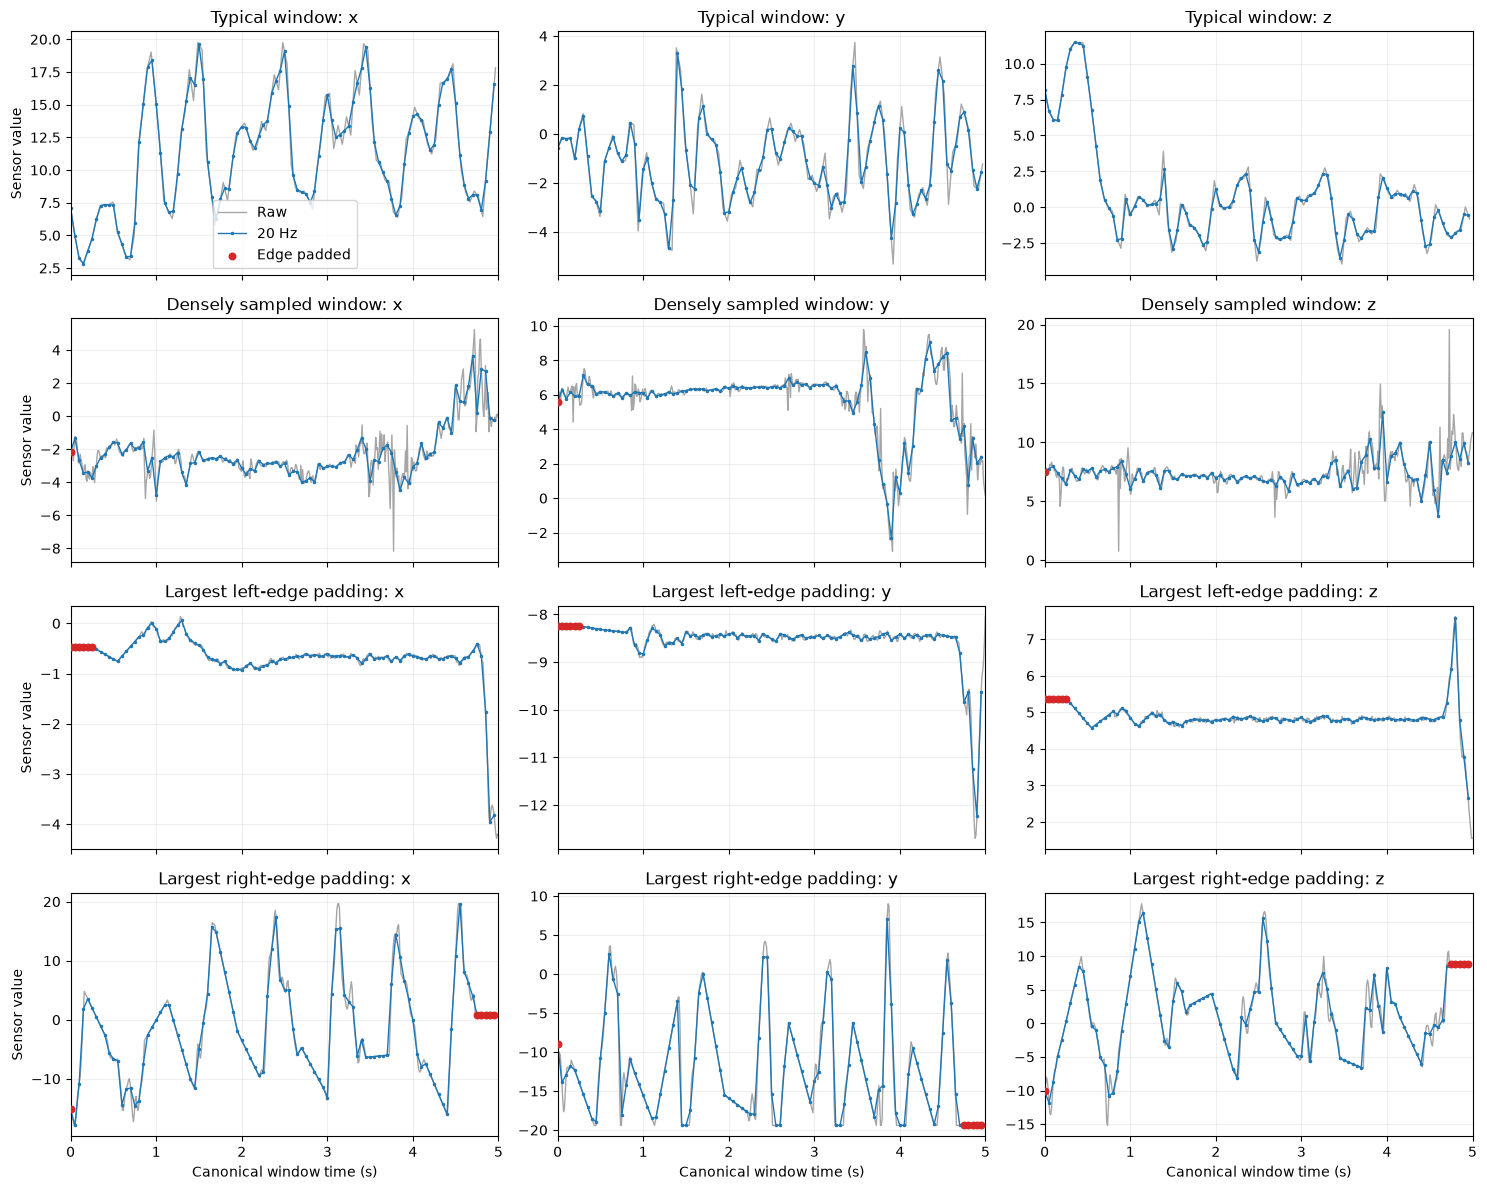

In [18]:
review_results = {}
review_diagnostics = []

for case, window_info in review_cases:
    (
        raw_window,
        raw_time_s,
        resampled_frame,
        diagnostics,
    ) = resample_window_for_review(window_info)

    review_results[case] = {
        "raw_window": raw_window,
        "raw_time_s": raw_time_s,
        "resampled": resampled_frame,
    }

    review_diagnostics.append({
        "case": case,
        **diagnostics,
    })

display(
    pd.DataFrame(review_diagnostics)
    .set_index("case")
)

fig, axes = plt.subplots(
    nrows=len(review_cases),
    ncols=len(SIGNAL_COLUMNS),
    figsize=(15, 12),
    sharex=True,
)

for row_index, (case, _) in enumerate(review_cases):
    result = review_results[case]

    for column_index, signal in enumerate(
        SIGNAL_COLUMNS
    ):
        ax = axes[row_index, column_index]

        ax.plot(
            result["raw_time_s"],
            result["raw_window"][signal],
            color="0.65",
            linewidth=1,
            label="Raw",
        )
        ax.plot(
            result["resampled"]["time_s"],
            result["resampled"][signal],
            color="tab:blue",
            linewidth=1,
            marker=".",
            markersize=3,
            label="20 Hz",
        )

        padded_mask = ~result[
            "resampled"
        ]["within_observed_range"]

        ax.scatter(
            result["resampled"].loc[
                padded_mask, "time_s"
            ],
            result["resampled"].loc[
                padded_mask, signal
            ],
            color="tab:red",
            s=22,
            label="Edge padded",
            zorder=3,
        )

        ax.set_title(f"{case}: {signal}")
        ax.set_xlim(0, WINDOW_DURATION_S)
        ax.grid(alpha=0.2)

        if column_index == 0:
            ax.set_ylabel("Sensor value")

        if row_index == len(review_cases) - 1:
            ax.set_xlabel("Canonical window time (s)")

axes[0, 0].legend()
plt.tight_layout()
plt.show()

### 4.5 Prototype-resampling findings

Timestamp interpolation closely reproduces the typical approximately 20 Hz
window.

For the densely sampled window, the 20 Hz representation preserves the broad
signal trajectory while omitting some narrow high-frequency spikes. This is an
expected consequence of downsampling and means that 20 Hz must remain
provisional until downstream validation is complete.

The two most extreme boundary examples require six padded target positions.
Nearest-edge padding creates short constant segments rather than unstable
extrapolation. Because padded points are not genuine observations, a separate
boolean coverage mask will be retained alongside each sequence.

The prototype is suitable for constructing candidate arrays. No artifacts are
saved yet, and no normalization is applied.

## 5. Build and validate fixed-length sequence arrays

### 5.1 Construct candidate arrays in memory

Each paired example is represented by:

- an accelerometer array with shape `(100, 3)`;
- a gyroscope array with shape `(100, 3)`;
- a boolean coverage mask for each sensor;
- metadata linking the array row to its source windows.

Array order follows the canonical paired metadata table. Signals are stored as
unnormalized `float32`; normalization remains a fold-specific modeling step.

In [19]:
def ordered_pair_metadata(split_name):
    return (
        paired_watch_windows
        .loc[
            paired_watch_windows["split"].eq(split_name)
        ]
        .sort_values(
            [
                "user_id",
                "activity_code",
                "window_position",
            ]
        )
        .reset_index(drop=True)
    )


train_pair_metadata = ordered_pair_metadata("train")
test_pair_metadata = ordered_pair_metadata("test")

window_grid_lookup = (
    valid_watch_windows_with_grid[
        [
            "window_id",
            "nominal_start_timestamp",
            "left_edge_padding_s",
            "right_edge_padding_s",
        ]
    ]
    .copy()
)

window_grid_lookup["window_id"] = (
    window_grid_lookup["window_id"].astype("string")
)

assert train_pair_metadata["pair_id"].is_unique
assert test_pair_metadata["pair_id"].is_unique
assert len(train_pair_metadata) == 25_585
assert len(test_pair_metadata) == 6_161

In [20]:
def build_resampled_sensor_array(
    samples,
    pair_metadata,
    sensor_name,
):
    source_id_column = f"{sensor_name}_window_id"

    window_plan = (
        pair_metadata[
            ["pair_id", source_id_column]
        ]
        .rename(
            columns={
                source_id_column: "window_id",
            }
        )
        .copy()
    )

    window_plan["array_index"] = np.arange(
        len(window_plan),
        dtype=np.int32,
    )
    window_plan["window_id"] = (
        window_plan["window_id"].astype("string")
    )

    window_plan = (
        window_plan
        .merge(
            window_grid_lookup,
            on="window_id",
            how="left",
            validate="one_to_one",
        )
        .sort_values("array_index")
        .reset_index(drop=True)
    )

    assert window_plan[
        "nominal_start_timestamp"
    ].notna().all()

    n_windows = len(window_plan)

    sequences = np.empty(
        (
            n_windows,
            TARGET_TIMESTEPS,
            len(SIGNAL_COLUMNS),
        ),
        dtype=np.float32,
    )
    coverage_mask = np.empty(
        (n_windows, TARGET_TIMESTEPS),
        dtype=bool,
    )
    filled = np.zeros(n_windows, dtype=bool)

    raw_sample_counts = np.empty(
        n_windows,
        dtype=np.int32,
    )
    left_padded_steps = np.empty(
        n_windows,
        dtype=np.int16,
    )
    right_padded_steps = np.empty(
        n_windows,
        dtype=np.int16,
    )
    largest_target_bracketing_gap_s = np.empty(
        n_windows,
        dtype=np.float32,
    )

    plan_by_window_id = (
        window_plan
        .assign(
            window_id_key=lambda frame: (
                frame["window_id"].astype(str)
            )
        )
        .set_index("window_id_key")
    )

    requested_window_ids = set(
        plan_by_window_id.index
    )

    source_rows = samples.loc[
        samples["sensor"].eq(sensor_name)
        & samples["window_id"].isin(
            requested_window_ids
        ),
        [
            "window_id",
            "timestamp",
            *SIGNAL_COLUMNS,
        ],
    ]

    for window_id, raw_window in source_rows.groupby(
        "window_id",
        observed=True,
        sort=False,
    ):
        window_key = str(window_id)

        if window_key not in plan_by_window_id.index:
            continue

        window_info = plan_by_window_id.loc[window_key]
        array_index = int(window_info["array_index"])

        nominal_start_timestamp = int(
            window_info["nominal_start_timestamp"]
        )

        raw_time_s = (
            raw_window["timestamp"].to_numpy(
                dtype=np.int64
            )
            - nominal_start_timestamp
        ) / 1e9

        raw_signals = raw_window[
            SIGNAL_COLUMNS
        ].to_numpy(dtype=np.float64)

        sequences[array_index] = np.column_stack([
            np.interp(
                TARGET_OFFSETS_S,
                raw_time_s,
                raw_signals[:, signal_index],
            )
            for signal_index in range(
                len(SIGNAL_COLUMNS)
            )
        ]).astype(np.float32)

        within_observed_range = (
            (TARGET_OFFSETS_S >= raw_time_s[0])
            & (TARGET_OFFSETS_S <= raw_time_s[-1])
        )
        coverage_mask[array_index] = (
            within_observed_range
        )

        insertion_positions = np.searchsorted(
            raw_time_s,
            TARGET_OFFSETS_S,
            side="left",
        )

        left_positions = np.clip(
            insertion_positions - 1,
            0,
            len(raw_time_s) - 1,
        )
        right_positions = np.clip(
            insertion_positions,
            0,
            len(raw_time_s) - 1,
        )

        bracketing_gap_s = (
            raw_time_s[right_positions]
            - raw_time_s[left_positions]
        )

        raw_sample_counts[array_index] = len(
            raw_window
        )
        left_padded_steps[array_index] = int(
            (TARGET_OFFSETS_S < raw_time_s[0]).sum()
        )
        right_padded_steps[array_index] = int(
            (TARGET_OFFSETS_S > raw_time_s[-1]).sum()
        )
        largest_target_bracketing_gap_s[
            array_index
        ] = float(
            bracketing_gap_s[
                within_observed_range
            ].max()
        )

        filled[array_index] = True

    assert filled.all()

    diagnostics = window_plan[
        [
            "array_index",
            "pair_id",
            "window_id",
            "left_edge_padding_s",
            "right_edge_padding_s",
        ]
    ].copy()

    diagnostics["raw_samples"] = raw_sample_counts
    diagnostics["left_padded_steps"] = (
        left_padded_steps
    )
    diagnostics["right_padded_steps"] = (
        right_padded_steps
    )
    diagnostics["edge_padded_steps"] = (
        left_padded_steps + right_padded_steps
    )
    diagnostics[
        "largest_target_bracketing_gap_s"
    ] = largest_target_bracketing_gap_s

    return sequences, coverage_mask, diagnostics

In [21]:
(
    train_accel_sequences,
    train_accel_coverage_mask,
    train_accel_resampling_diagnostics,
) = build_resampled_sensor_array(
    train_watch_samples,
    train_pair_metadata,
    "accel",
)

print("Built train accelerometer arrays.")

(
    train_gyro_sequences,
    train_gyro_coverage_mask,
    train_gyro_resampling_diagnostics,
) = build_resampled_sensor_array(
    train_watch_samples,
    train_pair_metadata,
    "gyro",
)

print("Built train gyroscope arrays.")

(
    test_accel_sequences,
    test_accel_coverage_mask,
    test_accel_resampling_diagnostics,
) = build_resampled_sensor_array(
    test_watch_samples,
    test_pair_metadata,
    "accel",
)

print("Built test accelerometer arrays.")

(
    test_gyro_sequences,
    test_gyro_coverage_mask,
    test_gyro_resampling_diagnostics,
) = build_resampled_sensor_array(
    test_watch_samples,
    test_pair_metadata,
    "gyro",
)

print("Built test gyroscope arrays.")

Built train accelerometer arrays.
Built train gyroscope arrays.
Built test accelerometer arrays.
Built test gyroscope arrays.


In [22]:
sequence_outputs = {
    ("train", "accel"): (
        train_accel_sequences,
        train_accel_coverage_mask,
        train_accel_resampling_diagnostics,
    ),
    ("train", "gyro"): (
        train_gyro_sequences,
        train_gyro_coverage_mask,
        train_gyro_resampling_diagnostics,
    ),
    ("test", "accel"): (
        test_accel_sequences,
        test_accel_coverage_mask,
        test_accel_resampling_diagnostics,
    ),
    ("test", "gyro"): (
        test_gyro_sequences,
        test_gyro_coverage_mask,
        test_gyro_resampling_diagnostics,
    ),
}

sequence_overview_rows = []

for (
    split_name,
    sensor_name,
), (
    sequences,
    coverage_mask,
    diagnostics,
) in sequence_outputs.items():
    expected_windows = (
        len(train_pair_metadata)
        if split_name == "train"
        else len(test_pair_metadata)
    )

    assert sequences.shape == (
        expected_windows,
        TARGET_TIMESTEPS,
        len(SIGNAL_COLUMNS),
    )
    assert coverage_mask.shape == (
        expected_windows,
        TARGET_TIMESTEPS,
    )
    assert sequences.dtype == np.float32
    assert coverage_mask.dtype == bool
    assert np.isfinite(sequences).all()
    assert len(diagnostics) == expected_windows
    assert diagnostics["array_index"].is_unique
    assert diagnostics["pair_id"].is_unique

    sequence_overview_rows.append({
        "split": split_name,
        "sensor": sensor_name,
        "shape": sequences.shape,
        "dtype": str(sequences.dtype),
        "array_mib": sequences.nbytes / 1024**2,
        "windows_with_padding": int(
            diagnostics["edge_padded_steps"]
            .gt(0)
            .sum()
        ),
        "padded_target_percent": (
            (~coverage_mask).mean() * 100
        ),
        "maximum_padded_steps": int(
            diagnostics["edge_padded_steps"].max()
        ),
        "maximum_target_bracketing_gap_s": (
            diagnostics[
                "largest_target_bracketing_gap_s"
            ].max()
        ),
    })

sequence_array_overview = pd.DataFrame(
    sequence_overview_rows
)

display(sequence_array_overview.round(4))

print("Candidate sequence-array validation passed.")

,split,sensor,shape,dtype,array_mib,windows_with_padding,padded_target_percent,maximum_padded_steps,maximum_target_bracketing_gap_s
0,train,accel,"(25585, 100, 3)",float32,29.2797,24855,0.9739,8,0.4837
1,train,gyro,"(25585, 100, 3)",float32,29.2797,24855,0.9739,8,0.4837
2,test,accel,"(6161, 100, 3)",float32,7.0507,5985,0.9719,3,0.2775
3,test,gyro,"(6161, 100, 3)",float32,7.0507,5984,0.9718,4,0.2775


Candidate sequence-array validation passed.


### 5.2 Validate row alignment and interpolation exposure

Before accepting the candidate arrays, we verify that:

- every array row follows the canonical paired-window order;
- accelerometer and gyroscope row `i` refer to the same pair;
- each source window ID matches the corresponding paired metadata;
- the number of false mask positions agrees with the recorded edge-padding count.

We also summarize multi-step boundary padding and unusually large
interpolation brackets. The test split is included only for structural
verification; preprocessing decisions remain based on the development data.

In [23]:
alignment_rows = []
padding_rows = []
gap_rows = []
worst_gap_rows = []

for (
    split_name,
    sensor_name,
), (
    sequences,
    coverage_mask,
    diagnostics,
) in sequence_outputs.items():
    pair_metadata = (
        train_pair_metadata
        if split_name == "train"
        else test_pair_metadata
    )

    source_id_column = f"{sensor_name}_window_id"

    expected_array_indices = np.arange(
        len(pair_metadata),
        dtype=np.int32,
    )

    assert np.array_equal(
        diagnostics["array_index"].to_numpy(),
        expected_array_indices,
    )

    assert np.array_equal(
        diagnostics["pair_id"].astype(str).to_numpy(),
        pair_metadata["pair_id"].astype(str).to_numpy(),
    )

    assert np.array_equal(
        diagnostics["window_id"].astype(str).to_numpy(),
        pair_metadata[source_id_column].astype(str).to_numpy(),
    )

    padded_steps_from_mask = (
        ~coverage_mask
    ).sum(axis=1)

    assert np.array_equal(
        padded_steps_from_mask,
        diagnostics["edge_padded_steps"].to_numpy(),
    )

    alignment_rows.append({
        "split": split_name,
        "sensor": sensor_name,
        "aligned_rows": len(diagnostics),
        "alignment_passed": True,
    })

    padded_steps = diagnostics[
        "edge_padded_steps"
    ]

    padding_rows.append({
        "split": split_name,
        "sensor": sensor_name,
        "no_padding": int(
            padded_steps.eq(0).sum()
        ),
        "one_step": int(
            padded_steps.eq(1).sum()
        ),
        "two_to_five_steps": int(
            padded_steps.between(2, 5).sum()
        ),
        "six_or_more_steps": int(
            padded_steps.ge(6).sum()
        ),
        "p99_padded_steps": float(
            padded_steps.quantile(0.99)
        ),
        "maximum_padded_steps": int(
            padded_steps.max()
        ),
    })

    maximum_gaps = diagnostics[
        "largest_target_bracketing_gap_s"
    ]

    gap_rows.append({
        "split": split_name,
        "sensor": sensor_name,
        "median_gap_s": maximum_gaps.median(),
        "p95_gap_s": maximum_gaps.quantile(0.95),
        "p99_gap_s": maximum_gaps.quantile(0.99),
        "maximum_gap_s": maximum_gaps.max(),
        "windows_over_0.10_s": int(
            maximum_gaps.gt(0.10).sum()
        ),
        "windows_over_0.20_s": int(
            maximum_gaps.gt(0.20).sum()
        ),
        "windows_over_0.30_s": int(
            maximum_gaps.gt(0.30).sum()
        ),
        "windows_over_0.40_s": int(
            maximum_gaps.gt(0.40).sum()
        ),
    })

    pair_context = pair_metadata[
        [
            "pair_id",
            "user_id",
            "activity_code",
            "window_position",
        ]
    ]

    worst_sensor_gaps = (
        diagnostics
        .nlargest(
            5,
            "largest_target_bracketing_gap_s",
        )
        .merge(
            pair_context,
            on="pair_id",
            how="left",
            validate="one_to_one",
        )
        .assign(
            split=split_name,
            sensor=sensor_name,
        )
    )

    worst_gap_rows.append(
        worst_sensor_gaps[
            [
                "split",
                "sensor",
                "pair_id",
                "window_id",
                "user_id",
                "activity_code",
                "window_position",
                "raw_samples",
                "edge_padded_steps",
                "largest_target_bracketing_gap_s",
            ]
        ]
    )

alignment_summary = pd.DataFrame(
    alignment_rows
)
padding_summary = pd.DataFrame(
    padding_rows
)
interpolation_gap_summary = pd.DataFrame(
    gap_rows
)
worst_interpolation_gaps = (
    pd.concat(
        worst_gap_rows,
        ignore_index=True,
    )
    .sort_values(
        "largest_target_bracketing_gap_s",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(alignment_summary)
display(padding_summary)
display(
    interpolation_gap_summary.round(4)
)
display(
    worst_interpolation_gaps.round(4)
)

print(
    "Array alignment and mask validation passed."
)

,split,sensor,aligned_rows,alignment_passed
0,train,accel,25585,True
1,train,gyro,25585,True
2,test,accel,6161,True
3,test,gyro,6161,True


,split,sensor,no_padding,one_step,two_to_five_steps,six_or_more_steps,p99_padded_steps,maximum_padded_steps
0,train,accel,730,24833,19,3,1.0,8
1,train,gyro,730,24831,22,2,1.0,8
2,test,accel,176,5983,2,0,1.0,3
3,test,gyro,177,5983,1,0,1.0,4


,split,sensor,median_gap_s,p95_gap_s,p99_gap_s,maximum_gap_s,windows_over_0.10_s,windows_over_0.20_s,windows_over_0.30_s,windows_over_0.40_s
0,train,accel,0.0499,0.05,0.0500,0.4837,178,138,21,2
1,train,gyro,0.0499,0.05,0.0678,0.4837,175,136,21,2
2,test,accel,0.0499,0.05,0.0500,0.2775,19,12,0,0
3,test,gyro,0.0499,0.05,0.0500,0.2775,18,11,0,0


,split,sensor,pair_id,window_id,user_id,activity_code,window_position,raw_samples,edge_padded_steps,largest_target_bracketing_gap_s
0,train,accel,1621_watch_pair_E_0032,1621_watch_accel_E_0032,1621,E,32,413,1,0.4837
1,train,gyro,1621_watch_pair_E_0032,1621_watch_gyro_E_0032,1621,E,32,409,1,0.4837
2,train,gyro,1609_watch_pair_K_0034,1609_watch_gyro_K_0034,1609,K,34,225,1,0.4090
3,train,accel,1609_watch_pair_K_0034,1609_watch_accel_K_0034,1609,K,34,225,1,0.4090
4,train,accel,1623_watch_pair_D_0032,1623_watch_accel_D_0032,1623,D,32,93,1,0.3782
5,train,gyro,1623_watch_pair_D_0032,1623_watch_gyro_D_0032,1623,D,32,93,1,0.3782
6,train,accel,1644_watch_pair_P_0009,1644_watch_accel_P_0009,1644,P,9,83,3,0.3588
7,train,gyro,1644_watch_pair_P_0009,1644_watch_gyro_P_0009,1644,P,9,84,2,0.3588
8,train,accel,1609_watch_pair_K_0028,1609_watch_accel_K_0028,1609,K,28,445,1,0.3239
9,train,gyro,1609_watch_pair_K_0028,1609_watch_gyro_K_0028,1609,K,28,445,1,0.3239


Array alignment and mask validation passed.


### 5.3 Sequence-array validation findings

All sequence rows follow the canonical paired-window order. Accelerometer and
gyroscope row `i` refer to the same pair, their source window IDs agree with
the paired metadata, and each coverage mask agrees with its recorded
edge-padding count.

Although approximately 97% of windows contain at least one padded target
position, the 99th percentile is only one padded position. This occurs because
the fixed grid begins at the nominal window boundary while the first physical
measurement usually arrives slightly afterward. Multi-step padding is rare
and confined to a small number of boundary exceptions.

The typical maximum interpolation bracket is approximately 0.05 seconds.
Fewer than 1% of development windows contain a bracket above 0.10 seconds,
and only two paired examples exceed 0.40 seconds. The largest gaps occur in
the same accelerometer and gyroscope pairs, indicating synchronized acquisition
interruptions rather than a resampling or pairing error.

All retained windows continue to satisfy the fixed 0.5-second maximum-gap
quality rule. No additional windows are excluded. Per-window padding and
interpolation diagnostics will be retained in the row metadata.

In [24]:
ROW_METADATA_COLUMNS = [
    "pair_id",
    "split",
    "user_id",
    "activity_code",
    "window_position",
    "fold",
    "accel_window_id",
    "gyro_window_id",
    "accel_n_samples",
    "gyro_n_samples",
    "accel_start_timestamp",
    "accel_end_timestamp",
    "gyro_start_timestamp",
    "gyro_end_timestamp",
    "accel_observed_span_s",
    "gyro_observed_span_s",
    "accel_max_gap_s",
    "gyro_max_gap_s",
    "start_offset_s",
    "end_offset_s",
    "overlap_s",
]


def build_sequence_metadata(
    pair_metadata,
    accel_diagnostics,
    gyro_diagnostics,
):
    metadata = (
        pair_metadata[ROW_METADATA_COLUMNS]
        .copy()
        .reset_index(drop=True)
    )

    metadata.insert(
        0,
        "array_index",
        np.arange(
            len(metadata),
            dtype=np.int32,
        ),
    )

    for sensor_name, diagnostics in [
        ("accel", accel_diagnostics),
        ("gyro", gyro_diagnostics),
    ]:
        diagnostics = (
            diagnostics
            .sort_values("array_index")
            .reset_index(drop=True)
        )

        assert np.array_equal(
            diagnostics["array_index"].to_numpy(),
            metadata["array_index"].to_numpy(),
        )
        assert np.array_equal(
            diagnostics["pair_id"].astype(str).to_numpy(),
            metadata["pair_id"].astype(str).to_numpy(),
        )
        assert np.array_equal(
            diagnostics["window_id"].astype(str).to_numpy(),
            metadata[
                f"{sensor_name}_window_id"
            ].astype(str).to_numpy(),
        )
        assert np.array_equal(
            diagnostics["raw_samples"].to_numpy(),
            metadata[
                f"{sensor_name}_n_samples"
            ].to_numpy(),
        )

        sensor_diagnostics = (
            diagnostics
            .merge(
                window_grid_lookup[
                    [
                        "window_id",
                        "nominal_start_timestamp",
                    ]
                ],
                on="window_id",
                how="left",
                validate="one_to_one",
            )
            [
                [
                    "array_index",
                    "pair_id",
                    "nominal_start_timestamp",
                    "left_edge_padding_s",
                    "right_edge_padding_s",
                    "left_padded_steps",
                    "right_padded_steps",
                    "edge_padded_steps",
                    "largest_target_bracketing_gap_s",
                ]
            ]
            .rename(
                columns={
                    column: f"{sensor_name}_{column}"
                    for column in [
                        "nominal_start_timestamp",
                        "left_edge_padding_s",
                        "right_edge_padding_s",
                        "left_padded_steps",
                        "right_padded_steps",
                        "edge_padded_steps",
                        "largest_target_bracketing_gap_s",
                    ]
                }
            )
        )

        metadata = metadata.merge(
            sensor_diagnostics,
            on=["array_index", "pair_id"],
            how="left",
            validate="one_to_one",
            sort=False,
        )

    metadata = (
        metadata
        .sort_values("array_index")
        .reset_index(drop=True)
    )

    return metadata


train_sequence_metadata = build_sequence_metadata(
    train_pair_metadata,
    train_accel_resampling_diagnostics,
    train_gyro_resampling_diagnostics,
)

test_sequence_metadata = build_sequence_metadata(
    test_pair_metadata,
    test_accel_resampling_diagnostics,
    test_gyro_resampling_diagnostics,
)

In [25]:
metadata_outputs = {
    "train": train_sequence_metadata,
    "test": test_sequence_metadata,
}

metadata_overview_rows = []

for split_name, metadata in metadata_outputs.items():
    expected_rows = (
        len(train_pair_metadata)
        if split_name == "train"
        else len(test_pair_metadata)
    )
    expected_subjects = (
        train_subject_ids
        if split_name == "train"
        else test_subject_ids
    )

    assert len(metadata) == expected_rows
    assert metadata["pair_id"].is_unique

    assert np.array_equal(
        metadata["array_index"].to_numpy(),
        np.arange(
            expected_rows,
            dtype=np.int32,
        ),
    )

    assert (
        sorted(metadata["user_id"].unique())
        == sorted(expected_subjects)
    )

    assert metadata[
        "activity_code"
    ].nunique() == 18

    assert metadata.drop(
        columns=["fold"]
    ).notna().all().all()

    if split_name == "train":
        assert metadata["fold"].notna().all()
        assert set(
            metadata["fold"].astype(int)
        ) == {1, 2, 3, 4, 5}
    else:
        assert metadata["fold"].isna().all()

    metadata_overview_rows.append({
        "split": split_name,
        "rows": len(metadata),
        "columns": metadata.shape[1],
        "subjects": metadata["user_id"].nunique(),
        "activities": metadata[
            "activity_code"
        ].nunique(),
        "unique_pairs": metadata[
            "pair_id"
        ].nunique(),
    })

activity_codes = sorted(
    train_sequence_metadata[
        "activity_code"
    ].astype(str).unique()
)

assert set(activity_codes) == set(
    test_sequence_metadata[
        "activity_code"
    ].astype(str).unique()
)

metadata_overview = pd.DataFrame(
    metadata_overview_rows
)

display(metadata_overview)
display(train_sequence_metadata.head(3))
display(test_sequence_metadata.head(3))

print("Activity-code order:", activity_codes)
print("Row-level metadata validation passed.")

,split,rows,columns,subjects,activities,unique_pairs
0,train,25585,36,41,18,25585
1,test,6161,36,10,18,6161


,array_index,pair_id,split,user_id,activity_code,window_position,fold,accel_window_id,gyro_window_id,accel_n_samples,...,accel_right_padded_steps,accel_edge_padded_steps,accel_largest_target_bracketing_gap_s,gyro_nominal_start_timestamp,gyro_left_edge_padding_s,gyro_right_edge_padding_s,gyro_left_padded_steps,gyro_right_padded_steps,gyro_edge_padded_steps,gyro_largest_target_bracketing_gap_s
0,0,1600_watch_pair_A_0000,train,1600,A,0,3,1600_watch_accel_A_0000,1600_watch_gyro_A_0000,101,...,0,0,0.049759,90426757696641,0.000000,0.0,0,0,0,0.049759
1,1,1600_watch_pair_A_0001,train,1600,A,1,3,1600_watch_accel_A_0001,1600_watch_gyro_A_0001,101,...,0,1,0.049822,90431757696641,0.016174,0.0,1,0,1,0.049822
2,2,1600_watch_pair_A_0002,train,1600,A,2,3,1600_watch_accel_A_0002,1600_watch_gyro_A_0002,100,...,0,1,0.049853,90436757696641,0.045951,0.0,1,0,1,0.049853


,array_index,pair_id,split,user_id,activity_code,window_position,fold,accel_window_id,gyro_window_id,accel_n_samples,...,accel_right_padded_steps,accel_edge_padded_steps,accel_largest_target_bracketing_gap_s,gyro_nominal_start_timestamp,gyro_left_edge_padding_s,gyro_right_edge_padding_s,gyro_left_padded_steps,gyro_right_padded_steps,gyro_edge_padded_steps,gyro_largest_target_bracketing_gap_s
0,0,1606_watch_pair_A_0000,test,1606,A,0,<NA>,1606_watch_accel_A_0000,1606_watch_gyro_A_0000,101,...,0,0,0.049727,802236442795351,0.000000,0.0,0,0,0,0.049727
1,1,1606_watch_pair_A_0001,test,1606,A,1,<NA>,1606_watch_accel_A_0001,1606_watch_gyro_A_0001,101,...,0,1,0.049799,802241442795351,0.013930,0.0,1,0,1,0.049799
2,2,1606_watch_pair_A_0002,test,1606,A,2,<NA>,1606_watch_accel_A_0002,1606_watch_gyro_A_0002,100,...,0,1,0.049831,802246442795351,0.040913,0.0,1,0,1,0.049831


Activity-code order: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'O', 'P', 'Q', 'R', 'S']
Row-level metadata validation passed.


## 6. Save shared preprocessing artifacts

The validated paired-watch representation is saved under
`modified/watch_pair_20hz/`.

Each split contains:

- unnormalized accelerometer and gyroscope arrays;
- sensor-specific edge-coverage masks;
- the common target-time grid;
- row metadata linking every array position to its subject, activity, fold,
  source windows, and resampling diagnostics.

A small JSON record documents the complete preprocessing contract. The JSON
file is written last so that its presence indicates that all dataset files
were successfully created.

In [26]:
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

TRAIN_SEQUENCE_PATH = (
    OUTPUT_DIR / "train_sequences.npz"
)
TEST_SEQUENCE_PATH = (
    OUTPUT_DIR / "test_sequences.npz"
)
TRAIN_SEQUENCE_METADATA_PATH = (
    OUTPUT_DIR / "train_metadata.parquet"
)
TEST_SEQUENCE_METADATA_PATH = (
    OUTPUT_DIR / "test_metadata.parquet"
)
PREPROCESSING_META_PATH = (
    OUTPUT_DIR / "preprocessing_meta.json"
)


np.savez_compressed(
    TRAIN_SEQUENCE_PATH,
    accel=train_accel_sequences,
    gyro=train_gyro_sequences,
    accel_coverage_mask=train_accel_coverage_mask,
    gyro_coverage_mask=train_gyro_coverage_mask,
    target_offsets_s=TARGET_OFFSETS_S.astype(
        np.float32
    ),
)

np.savez_compressed(
    TEST_SEQUENCE_PATH,
    accel=test_accel_sequences,
    gyro=test_gyro_sequences,
    accel_coverage_mask=test_accel_coverage_mask,
    gyro_coverage_mask=test_gyro_coverage_mask,
    target_offsets_s=TARGET_OFFSETS_S.astype(
        np.float32
    ),
)

train_sequence_metadata.to_parquet(
    TRAIN_SEQUENCE_METADATA_PATH,
    index=False,
)

test_sequence_metadata.to_parquet(
    TEST_SEQUENCE_METADATA_PATH,
    index=False,
)


def relative_path(path):
    return str(path.relative_to(PROJECT_ROOT))


def array_shape(array):
    return [
        int(dimension)
        for dimension in array.shape
    ]


def split_count_record(split_name):
    return {
        "input_sensor_windows": {
            sensor_name: int(
                quality_filter_summary.loc[
                    (split_name, sensor_name),
                    "windows_before",
                ]
            )
            for sensor_name in ["accel", "gyro"]
        },
        "quality_excluded_windows": {
            sensor_name: int(
                quality_filter_summary.loc[
                    (split_name, sensor_name),
                    "windows_removed",
                ]
            )
            for sensor_name in ["accel", "gyro"]
        },
        "valid_sensor_windows": {
            sensor_name: int(
                quality_filter_summary.loc[
                    (split_name, sensor_name),
                    "windows_retained",
                ]
            )
            for sensor_name in ["accel", "gyro"]
        },
        "unmatched_valid_windows": {
            "accel_only": int(
                pairing_overview.loc[
                    split_name,
                    "accel_only",
                ]
            ),
            "gyro_only": int(
                pairing_overview.loc[
                    split_name,
                    "gyro_only",
                ]
            ),
        },
        "paired_output_examples": int(
            len(metadata_outputs[split_name])
        ),
    }


preprocessing_meta = {
    "schema_version": 1,
    "artifact_name": "paired_watch_20hz",
    "stage": "shared_sequence_preprocessing",
    "source_files": {
        "train_samples": relative_path(
            TRAIN_SAMPLES_PATH
        ),
        "test_samples": relative_path(
            TEST_SAMPLES_PATH
        ),
        "windowed_split_metadata": relative_path(
            WINDOWED_META_PATH
        ),
        "canonical_split_metadata": relative_path(
            SPLIT_META_PATH
        ),
        "development_folds": relative_path(
            DEVELOPMENT_FOLDS_PATH
        ),
    },
    "canonical_window_protocol": {
        "duration_s": float(
            split_meta["window_s"]
        ),
        "minimum_samples": int(
            split_meta["min_samples"]
        ),
        "overlap": False,
    },
    "quality_rules": {
        "minimum_observed_span_s": (
            float(MIN_OBSERVED_SPAN_S)
        ),
        "maximum_internal_gap_s": (
            float(MAX_INTERNAL_GAP_S)
        ),
    },
    "pairing": {
        "device": "watch",
        "required_sensors": [
            "accel",
            "gyro",
        ],
        "keys": list(PAIR_KEYS),
        "policy": (
            "Inner intersection of valid accelerometer "
            "and gyroscope windows; missing streams are "
            "not synthesized."
        ),
        "alignment_policy": (
            "Each sensor is resampled on its own nominal "
            "window timeline; no cross-sensor absolute-time "
            "interpolation is applied."
        ),
    },
    "resampling": {
        "target_rate_hz": int(TARGET_RATE_HZ),
        "target_timesteps": int(
            TARGET_TIMESTEPS
        ),
        "first_offset_s": float(
            TARGET_OFFSETS_S[0]
        ),
        "last_offset_s": float(
            TARGET_OFFSETS_S[-1]
        ),
        "grid_endpoint": "excluded",
        "interpolation": (
            "Linear timestamp interpolation using numpy.interp"
        ),
        "edge_policy": (
            "Constant nearest-observed-value padding"
        ),
        "coverage_mask_semantics": (
            "True when the target timestamp lies inside "
            "the observed source interval"
        ),
        "anti_alias_filter": "none",
        "channel_order": list(SIGNAL_COLUMNS),
        "signal_dtype": "float32",
        "normalization": "none",
    },
    "labels": {
        "target_column": "activity_code",
        "activity_codes_in_order": activity_codes,
    },
    "subjects": {
        "train": list(train_subject_ids),
        "test": list(test_subject_ids),
        "development_fold_source": relative_path(
            DEVELOPMENT_FOLDS_PATH
        ),
    },
    "counts": {
        split_name: split_count_record(split_name)
        for split_name in ["train", "test"]
    },
    "outputs": {
        "train_sequences": {
            "file": relative_path(
                TRAIN_SEQUENCE_PATH
            ),
            "accel_shape": array_shape(
                train_accel_sequences
            ),
            "gyro_shape": array_shape(
                train_gyro_sequences
            ),
        },
        "test_sequences": {
            "file": relative_path(
                TEST_SEQUENCE_PATH
            ),
            "accel_shape": array_shape(
                test_accel_sequences
            ),
            "gyro_shape": array_shape(
                test_gyro_sequences
            ),
        },
        "train_metadata": {
            "file": relative_path(
                TRAIN_SEQUENCE_METADATA_PATH
            ),
            "rows": int(
                len(train_sequence_metadata)
            ),
        },
        "test_metadata": {
            "file": relative_path(
                TEST_SEQUENCE_METADATA_PATH
            ),
            "rows": int(
                len(test_sequence_metadata)
            ),
        },
        "npz_keys": [
            "accel",
            "gyro",
            "accel_coverage_mask",
            "gyro_coverage_mask",
            "target_offsets_s",
        ],
        "metadata_columns": list(
            train_sequence_metadata.columns
        ),
    },
    "development_status": (
        "20 Hz is the current shared candidate representation. "
        "Its usefulness will be evaluated only with the fixed "
        "development folds before final held-out testing."
    ),
}

PREPROCESSING_META_PATH.write_text(
    json.dumps(
        preprocessing_meta,
        indent=2,
    )
    + "\n",
    encoding="utf-8",
)


artifact_overview = pd.DataFrame([
    {
        "artifact": path.name,
        "path": relative_path(path),
        "size_mib": path.stat().st_size / 1024**2,
    }
    for path in [
        TRAIN_SEQUENCE_PATH,
        TEST_SEQUENCE_PATH,
        TRAIN_SEQUENCE_METADATA_PATH,
        TEST_SEQUENCE_METADATA_PATH,
        PREPROCESSING_META_PATH,
    ]
])

display(artifact_overview.round(4))

print("Shared preprocessing artifacts saved.")

,artifact,path,size_mib
0,train_sequences.npz,modified/watch_pair_20hz/train_sequences.npz,54.1783
1,test_sequences.npz,modified/watch_pair_20hz/test_sequences.npz,12.9659
2,train_metadata.parquet,modified/watch_pair_20hz/train_metadata.parquet,4.7753
3,test_metadata.parquet,modified/watch_pair_20hz/test_metadata.parquet,2.0195
4,preprocessing_meta.json,modified/watch_pair_20hz/preprocessing_meta.json,0.0054


Shared preprocessing artifacts saved.


## 7. Preprocessing findings and downstream contract

Shared preprocessing produced 25,585 development examples and 6,161 reserved
test examples. Every example contains separate watch accelerometer and
gyroscope sequences with shape `(100, 3)`, representing a 20 Hz timestamp grid
from 0.00 through 4.95 seconds.

Six development sensor windows failed the fixed temporal-quality rules.
Following quality filtering, 120 development and 79 test accelerometer windows
without gyroscope partners were excluded rather than synthesized. All expected
subjects and all 18 activities remain represented.

Signals were resampled independently on their sensor-specific nominal timelines
using linear timestamp interpolation and nearest-value edge padding. Padding is
limited: approximately 0.97% of target positions are padded, and 99% of windows
require no more than one padded position. Sensor-specific coverage masks and
resampling diagnostics are retained.

The saved representation is unnormalized `float32`. Downstream models must fit
normalization or other learned transformations using only the training subjects
within each development fold.

The downstream data contract is:

- array row `i` corresponds to metadata `array_index == i`;
- `activity_code` is the prediction target;
- `user_id` defines subject independence;
- `fold` provides the fixed development-fold assignment;
- accelerometer and gyroscope channels are ordered as `x, y, z`;
- test labels must not be used for model selection or preprocessing decisions.

The artifacts are stored under `modified/watch_pair_20hz/`. The 20 Hz
representation is the current development candidate and will next be assessed
with a Random Forest parity experiment using the fixed development folds.